# STATIONARITY + ADF + DIFFERENCING

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [5]:
df = pd.read_csv("Rossman_store.csv")
df.head()

/var/folders/k7/46l_krw10jng39xg1fqdnppc0000gn/T/ipykernel_55253/219373256.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
df.shape

(1017209, 9)

In [7]:
# Select Store 800
store_800 = df[df["Store"] == 800].copy()

# Convert Date to datetime
store_800["Date"] = pd.to_datetime(store_800["Date"])

# Sort chronologically and set Date as the index
store_800 = store_800.sort_values("Date")
store_800 = store_800.set_index("Date")

# Keep the daily Sales series
sales = store_800["Sales"].asfreq("D")

print("Observations:", len(sales))
print("Start date:", sales.index.min())
print("End date:", sales.index.max())
print("Missing sales values:", sales.isna().sum())

Observations: 942
Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00
Missing sales values: 0


In [8]:
# Forecast horizon: final 42 days
horizon = 42

train = sales.iloc[:-horizon]
test = sales.iloc[-horizon:]

print("Training observations:", len(train))
print("Test observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Training observations: 900
Test observations: 42
Training period: 2013-01-01 00:00:00 to 2015-06-19 00:00:00
Test period: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


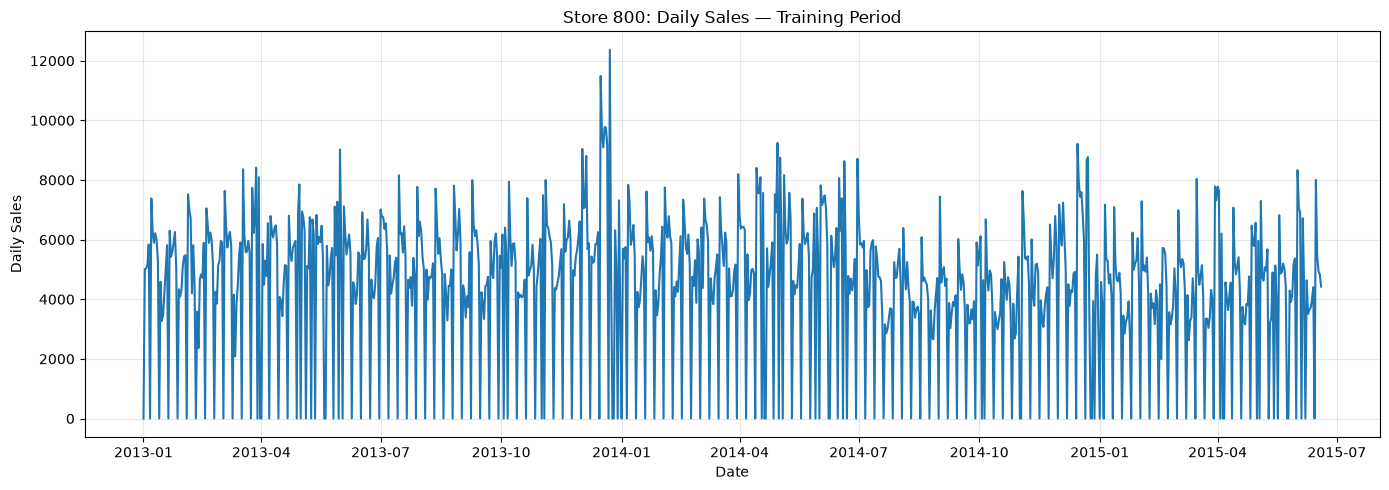

In [9]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values)
plt.title("Store 800: Daily Sales — Training Period")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ADF TESTING

In [12]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(train.dropna())

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])

ADF Statistic: -3.761761067802686
p-value: 0.003323694807797
Critical Values: {'1%': np.float64(-3.437819842246547), '5%': np.float64(-2.8648374649929753), '10%': np.float64(-2.5685258078777093)}


In [14]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.2/594.2 kB 7.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 6.6 MB/s  0:00:00m 6.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pmdarima]━━ 1/2 [pmdarima]


In [16]:
import pmdarima as pm

In [17]:
d = pm.arima.ndiffs(train.dropna(), test="adf")
print("Suggested ordinary differencing order (d):", d)

Suggested ordinary differencing order (d): 0


In [18]:
D = pm.arima.nsdiffs(train.dropna(), m=7, test="ocsb")
print("Suggested seasonal differencing order (D):", D)

Suggested seasonal differencing order (D): 0


In [19]:
from statsmodels.tsa.stattools import adfuller

# First-order differencing
train_diff = train.diff().dropna()

# Run the second ADF test
adf_result_2 = adfuller(train_diff)

print("Second ADF Test Results")
print("ADF Statistic:", adf_result_2[0])
print("p-value:", adf_result_2[1])
print("Lags Used:", adf_result_2[2])
print("Observations Used:", adf_result_2[3])

print("\nCritical Values:")
for key, value in adf_result_2[4].items():
    print(f"{key}: {value}")

if adf_result_2[1] < 0.05:
    print("\nConclusion: Reject the unit-root null hypothesis.")
    print("The differenced series is stationary according to the ADF test.")
else:
    print("\nConclusion: Fail to reject the unit-root null hypothesis.")
    print("The differenced series is not confirmed stationary by the ADF test.")

Second ADF Test Results
ADF Statistic: -11.802328244824926
p-value: 9.267704952345829e-22
Lags Used: 21
Observations Used: 877

Critical Values:
1%: -3.4378283848659277
5%: -2.864841231335243
10%: -2.5685278140988053

Conclusion: Reject the unit-root null hypothesis.
The differenced series is stationary according to the ADF test.


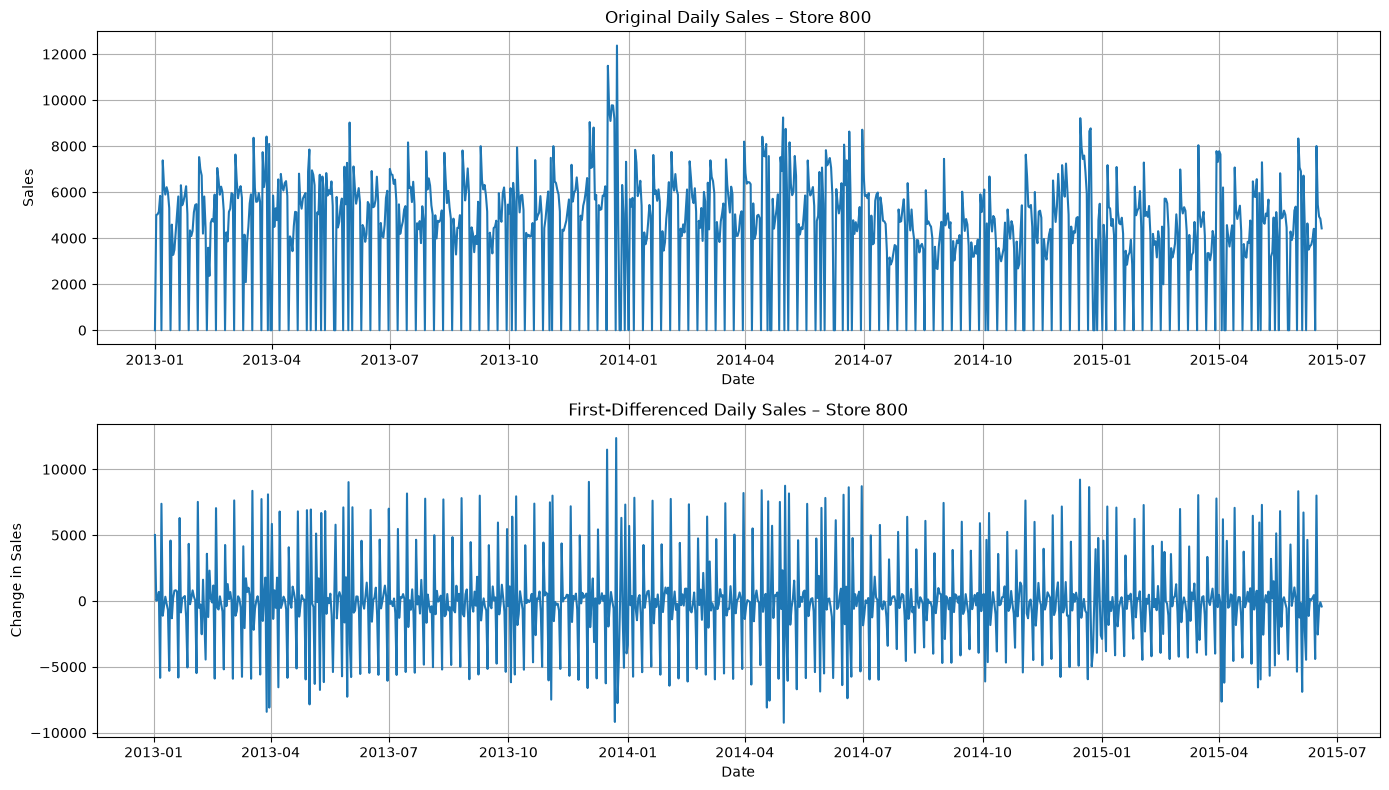

In [20]:
import matplotlib.pyplot as plt

# Plot original and differenced sales series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Original sales series
axes[0].plot(train.index, train)
axes[0].set_title("Original Daily Sales – Store 800")
axes[0].set_ylabel("Sales")
axes[0].set_xlabel("Date")
axes[0].grid(True)

# First-differenced sales series
axes[1].plot(train_diff.index, train_diff)
axes[1].set_title("First-Differenced Daily Sales – Store 800")
axes[1].set_ylabel("Change in Sales")
axes[1].set_xlabel("Date")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Key Findings and Conclusion: Stationarity, ADF and Differencing

## 1. Original Series: ADF Test

The original Store 800 training series contained 900 daily observations.

- **ADF statistic:** −3.7618
- **p-value:** 0.003323
- **Lags used:** 21
- **Observations used:** 878
- **5% critical value:** −2.8648

**Finding:** The p-value was below 0.05, so the unit-root null hypothesis was rejected. The result provides evidence against a unit root in the original series.

## 2. First-Differenced Series: ADF Test

First-order differencing was applied to calculate day-to-day changes in sales.

- **ADF statistic:** −11.8023
- **p-value:** 9.2677 × 10⁻²²
- **Lags used:** 21
- **Observations used:** 877
- **5% critical value:** −2.8648

**Finding:** The unit-root null hypothesis was also rejected for the differenced series.

## 3. Differencing and Visual Assessment

The `pmdarima` procedures recommended:

- Ordinary differencing: **d = 0**
- Seasonal differencing: **D = 0**
- Weekly seasonal period: **m = 7**

The plots compare the original sales levels with day-to-day changes in sales. The differenced series provides a different view of sales fluctuations, while visual inspection alone cannot establish stationarity.

## 4. Overall Conclusion and Handoff

The original series provided evidence against a unit root, and the selected differencing procedures recommended no ordinary or seasonal differencing. The first-differenced series was also found to provide evidence against a unit root, but differencing was not indicated as necessary for the original series.